In [114]:
%pip install dmba

Note: you may need to restart the kernel to use updated packages.


In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score

from dmba import classificationSummary 

%matplotlib inline

In [116]:
np.random.seed(1)

# read the right worksheet from excel
data = pd.read_excel("ebayAuctions.xlsx", sheet_name="eBay Auctions")

# analyze size of observations with null values
print(data.shape)
data.info()

(1972, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1972 entries, 0 to 1971
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   str    
 1   Currency      1972 non-null   str    
 2   sellerRating  1972 non-null   int64  
 3   Duration      1972 non-null   int64  
 4   endDay        1972 non-null   str    
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1972 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 123.4 KB


In [117]:
# nonnull values = rows for all columns so we proceed with data processing
# we begin by creating dummy variables and removing original categorical columns as requested

dummy_columns = ["Category", "Currency", "endDay", "Duration"]
for column in dummy_columns:
    if data[column].dtype != "string":
        data[column] = data[column].astype(str)
    
data = pd.get_dummies(data, columns = dummy_columns, drop_first=True)

In [118]:
# we now evaluate the numerical columns and check for their distributions and outliers
# Since we are working on a decision tree, the tree will find logical splits and we can keep them as numbers
    # Though I did realize this late and made a rudimentary splitting based on histograms
# Let's ensure that they are numbers

numerical_columns = ["sellerRating", "OpenPrice", "ClosePrice"]
for column in numerical_columns:
    if data[column].dtype != "float64" and data[column].dtype != "int64":
        data[column] = pd.to_numeric(data[column], errors='coerce')

# We can actually drop the closeprice since we will not have this in the incoming data
# turns out we do this later in the asignment - will keep here for now, and give data different name
data_noclose = data.drop(columns=["ClosePrice"])

# Let's now set the target variable to be boolean and move it to the end

data["Competitive?"] = data["Competitive?"].astype(bool)
data["Competitive?"] = data.pop("Competitive?")

# Double check
# print(data.shape)
# data.info()

In [119]:
# Data processing complete, ready for modeling
# Creating splits

X = data.drop(columns=['Competitive?'])
y = data['Competitive?']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1)

# print("Training set size:", X_train.shape)
# print("Test set size:", X_test.shape)

# Creating decision tree, min_samples_leaf = 50
fullClassTree = DecisionTreeClassifier(min_samples_leaf=50, random_state = 1)
fullClassTree.fit(X_train, y_train)

#evaluation train accuracy
print("Training Accuracy (WITH CLOSE PRICE):")
classificationSummary(y_train, fullClassTree.predict(X_train))
# (8:32 pm 24 Nov) 78% - open to suggestions on how to improve accuracy


Training Accuracy (WITH CLOSE PRICE):
Confusion Matrix (Accuracy 0.8301)

       Prediction
Actual   0   1
     0 466  82
     1 119 516


In [120]:
# visualizing the tree
print("Decision Tree Representation (WITH CLOSE PRICE):")
feature_names = list(X.columns)
text_representation = tree.export_text(fullClassTree, feature_names = feature_names)
print(text_representation)

# Let's now use data_noclose to compare accuracy

data_noclose["Competitive?"] = data_noclose["Competitive?"].astype(bool)
data_noclose["Competitive?"] = data_noclose.pop("Competitive?")

# Double check
# print(data_noclose.shape)
# data_noclose.info()

Decision Tree Representation (WITH CLOSE PRICE):
|--- OpenPrice <= 3.62
|   |--- ClosePrice <= 3.64
|   |   |--- OpenPrice <= 1.12
|   |   |   |--- class: True
|   |   |--- OpenPrice >  1.12
|   |   |   |--- OpenPrice <= 2.45
|   |   |   |   |--- class: False
|   |   |   |--- OpenPrice >  2.45
|   |   |   |   |--- class: False
|   |--- ClosePrice >  3.64
|   |   |--- Duration_10 <= 0.50
|   |   |   |--- class: True
|   |   |--- Duration_10 >  0.50
|   |   |   |--- class: True
|--- OpenPrice >  3.62
|   |--- ClosePrice <= 10.00
|   |   |--- OpenPrice <= 4.97
|   |   |   |--- class: False
|   |   |--- OpenPrice >  4.97
|   |   |   |--- ClosePrice <= 6.82
|   |   |   |   |--- class: False
|   |   |   |--- ClosePrice >  6.82
|   |   |   |   |--- OpenPrice <= 7.99
|   |   |   |   |   |--- class: False
|   |   |   |   |--- OpenPrice >  7.99
|   |   |   |   |   |--- class: False
|   |--- ClosePrice >  10.00
|   |   |--- OpenPrice <= 10.97
|   |   |   |--- OpenPrice <= 9.89
|   |   |   |   |--

In [121]:
# Checking the importance of each feature: Reference: Page 352 of Gerhard's book
importance = pd.Series(
    fullClassTree.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

OpenPrice                        0.503372
ClosePrice                       0.450075
sellerRating                     0.045881
Duration_10                      0.000672
Duration_5                       0.000000
Duration_3                       0.000000
endDay_Wed                       0.000000
endDay_Tue                       0.000000
Category_Pottery/Glass           0.000000
endDay_Sun                       0.000000
endDay_Sat                       0.000000
endDay_Mon                       0.000000
Currency_US                      0.000000
Currency_GBP                     0.000000
Category_Toys/Hobbies            0.000000
Category_SportingGoods           0.000000
endDay_Thu                       0.000000
Category_Photography             0.000000
Category_Music/Movie/Game        0.000000
Category_Jewelry                 0.000000
Category_Home/Garden             0.000000
Category_Health/Beauty           0.000000
Category_EverythingElse          0.000000
Category_Electronics             0

In [122]:
# Data processing complete, ready for modeling
# Creating splits

X_noclose = data_noclose.drop(columns=['Competitive?'])
y_noclose = data_noclose['Competitive?']
X_train, X_test, y_train, y_test = train_test_split(X_noclose, y_noclose, test_size=0.4, random_state=1)

# print("Training set size:", X_train.shape)
# print("Test set size:", X_test.shape)

# Creating decision tree, min_samples_leaf = 50
noCloseTree = DecisionTreeClassifier(min_samples_leaf=50, random_state = 1)
noCloseTree.fit(X_train, y_train)

#evaluation train accuracy
print("Training Accuracy (WITHOUT CLOSE PRICE):")
classificationSummary(y_train, noCloseTree.predict(X_train))
# (8:32 pm 24 Nov) 78% - open to suggestions on how to improve accuracy


Training Accuracy (WITHOUT CLOSE PRICE):
Confusion Matrix (Accuracy 0.7244)

       Prediction
Actual   0   1
     0 398 150
     1 176 459


In [123]:
importance = pd.Series(
    noCloseTree.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

OpenPrice                        0.604591
sellerRating                     0.343607
Category_Toys/Hobbies            0.028649
Category_Music/Movie/Game        0.023152
Category_SportingGoods           0.000000
Duration_5                       0.000000
Duration_3                       0.000000
Duration_10                      0.000000
endDay_Wed                       0.000000
endDay_Tue                       0.000000
endDay_Thu                       0.000000
endDay_Sun                       0.000000
endDay_Sat                       0.000000
endDay_Mon                       0.000000
Currency_US                      0.000000
Currency_GBP                     0.000000
Category_Photography             0.000000
Category_Pottery/Glass           0.000000
Category_Jewelry                 0.000000
Category_Home/Garden             0.000000
Category_Health/Beauty           0.000000
Category_EverythingElse          0.000000
Category_Electronics             0.000000
Category_Computer                0

In [124]:
# visualizing the tree
print("Decision Tree Representation (WITHOUT CLOSE PRICE):")
feature_names = list(X_noclose.columns)
text_representation = tree.export_text(noCloseTree, feature_names = feature_names)
print(text_representation)

Decision Tree Representation (WITHOUT CLOSE PRICE):
|--- OpenPrice <= 3.62
|   |--- OpenPrice <= 1.12
|   |   |--- sellerRating <= 3138.50
|   |   |   |--- class: True
|   |   |--- sellerRating >  3138.50
|   |   |   |--- class: True
|   |--- OpenPrice >  1.12
|   |   |--- sellerRating <= 2483.00
|   |   |   |--- sellerRating <= 1099.50
|   |   |   |   |--- OpenPrice <= 1.24
|   |   |   |   |   |--- class: True
|   |   |   |   |--- OpenPrice >  1.24
|   |   |   |   |   |--- class: True
|   |   |   |--- sellerRating >  1099.50
|   |   |   |   |--- OpenPrice <= 3.32
|   |   |   |   |   |--- class: True
|   |   |   |   |--- OpenPrice >  3.32
|   |   |   |   |   |--- class: True
|   |   |--- sellerRating >  2483.00
|   |   |   |--- class: False
|--- OpenPrice >  3.62
|   |--- sellerRating <= 601.50
|   |   |--- sellerRating <= 128.00
|   |   |   |--- class: True
|   |   |--- sellerRating >  128.00
|   |   |   |--- class: True
|   |--- sellerRating >  601.50
|   |   |--- Category_Toys/Hobbi

In [125]:
# Explore just USD Listed listings, focusing only on Close, open price and seller rating

# OpenPrice                        0.492623
# sellerRating                     0.257343
# Category_Collectibles            0.041999
# Category_Music/Movie/Game        0.031233
# Category_Books                   0.031218
# Category_Toys/Hobbies            0.020334
# Duration_7                       0.017818

### CHANGE THESE TO A SUBSET TO EVALUATE
keep_cols = [
    "Category_Toys/Hobbies",
    "OpenPrice",
    "sellerRating",
    "Category_Music/Movie/Game",
]

X_reduced = data[keep_cols]
y = data["Competitive?"]

X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = (
    train_test_split(X_reduced, y, test_size=0.4, random_state=1)
)

reducedTreeNoClose = DecisionTreeClassifier(min_samples_leaf=50, random_state=1)
reducedTreeNoClose.fit(X_train_reduced, y_train_reduced)


# print("Training Set Performance")
# classificationSummary(y_train_reduced, reducedTreeNoClose.predict(X_train_reduced))


# keep_cols = ['OpenPrice', 'sellerRating', 'Category_Music/Movie/Game','Category_Toys/Hobbies']
# X = data[keep_cols]
# y = data['Competitive?']
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1)

# reducedTreeNoClose = DecisionTreeClassifier(min_samples_leaf=50, random_state = 1)
# reducedTreeNoClose.fit(X_train, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [126]:
print("Training Accuracy (Reduced Model WITHOUT ClosePrice):")
classificationSummary(y_train_reduced, reducedTreeNoClose.predict(X_train_reduced))

#print("Test Accuracy (Reduced Model WITH ClosePrice):")
print("Test Accuracy (Reduced Model WITHOUT ClosePrice):")
reduced_test_predictions = reducedTreeNoClose.predict(X_test_reduced)
classificationSummary(y_test_reduced, reduced_test_predictions)

Training Accuracy (Reduced Model WITHOUT ClosePrice):
Confusion Matrix (Accuracy 0.7244)

       Prediction
Actual   0   1
     0 398 150
     1 176 459
Test Accuracy (Reduced Model WITHOUT ClosePrice):
Confusion Matrix (Accuracy 0.7224)

       Prediction
Actual   0   1
     0 263  95
     1 124 307


In [127]:
# plot tree diagram
# feature_names = list(X.columns)
feature_names = list(reducedTreeNoClose.feature_names_in_)
text_representation = tree.export_text(reducedTreeNoClose, feature_names = feature_names)
print(text_representation)

|--- OpenPrice <= 3.62
|   |--- OpenPrice <= 1.12
|   |   |--- sellerRating <= 3138.50
|   |   |   |--- class: True
|   |   |--- sellerRating >  3138.50
|   |   |   |--- class: True
|   |--- OpenPrice >  1.12
|   |   |--- sellerRating <= 2483.00
|   |   |   |--- sellerRating <= 1099.50
|   |   |   |   |--- OpenPrice <= 1.24
|   |   |   |   |   |--- class: True
|   |   |   |   |--- OpenPrice >  1.24
|   |   |   |   |   |--- class: True
|   |   |   |--- sellerRating >  1099.50
|   |   |   |   |--- OpenPrice <= 3.32
|   |   |   |   |   |--- class: True
|   |   |   |   |--- OpenPrice >  3.32
|   |   |   |   |   |--- class: True
|   |   |--- sellerRating >  2483.00
|   |   |   |--- class: False
|--- OpenPrice >  3.62
|   |--- sellerRating <= 601.50
|   |   |--- sellerRating <= 128.00
|   |   |   |--- class: True
|   |   |--- sellerRating >  128.00
|   |   |   |--- class: True
|   |--- sellerRating >  601.50
|   |   |--- Category_Toys/Hobbies <= 0.50
|   |   |   |--- Category_Music/Movie/Gam

In [128]:
keep_cols = [
    'ClosePrice', 
    'OpenPrice', 
    'sellerRating', 
    'Duration_10'
]

X_reduced_close = data[keep_cols]
y = data["Competitive?"]

X_train_reduced_close, X_test_reduced_close, y_train_reduced_close, y_test_reduced_close = (
    train_test_split(X_reduced_close, y, test_size=0.4, random_state=1)
)

reducedTree = DecisionTreeClassifier(min_samples_leaf=50, random_state=1)
reducedTree.fit(X_train_reduced_close, y_train_reduced_close)


# keep_cols = ['ClosePrice', 'OpenPrice', 'sellerRating', 'Duration_10']
# X = data[keep_cols]
# y = data['Competitive?']
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1)

# reducedTree = DecisionTreeClassifier(min_samples_leaf=50, random_state = 1)
# reducedTree.fit(X_train, y_train)

# print("Training Accuracy (Reduced Model WITH ClosePrice):")
# classificationSummary(y_train, reducedTree.predict(X_train))

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [129]:
# param_grid = {'max_depth': [2, 3, 4, 5, 6, 7, 8, 9, 10]}
# gridSearch = GridSearchCV(fullClassTree, param_grid, cv=5)
# gridSearch.fit(X_train, y_train)
# print('Initial Score:', gridSearch.best_score_)
# print('Best Parameters:', gridSearch.best_params_)

In [130]:
print("Training Accuracy (Reduced Model WITH ClosePrice):")
classificationSummary(y_train_reduced_close, reducedTree.predict(X_train_reduced_close))

print("Test Accuracy (Reduced Model WITH ClosePrice):")
reduced_test_predictions_close = reducedTree.predict(X_test_reduced_close)
classificationSummary(y_test_reduced_close, reduced_test_predictions_close)

Training Accuracy (Reduced Model WITH ClosePrice):
Confusion Matrix (Accuracy 0.8301)

       Prediction
Actual   0   1
     0 466  82
     1 119 516
Test Accuracy (Reduced Model WITH ClosePrice):
Confusion Matrix (Accuracy 0.8048)

       Prediction
Actual   0   1
     0 305  53
     1 101 330


## Visualization of the Final Decision Tree

### Tree Diagram

In [ ]:
feature_names = list(reducedTreeNoClose.feature_names_in_)

In [ ]:
class_names = ['Non-Competitive', 'Competitive']
class_names

['Non-Competitive', 'Competitive']

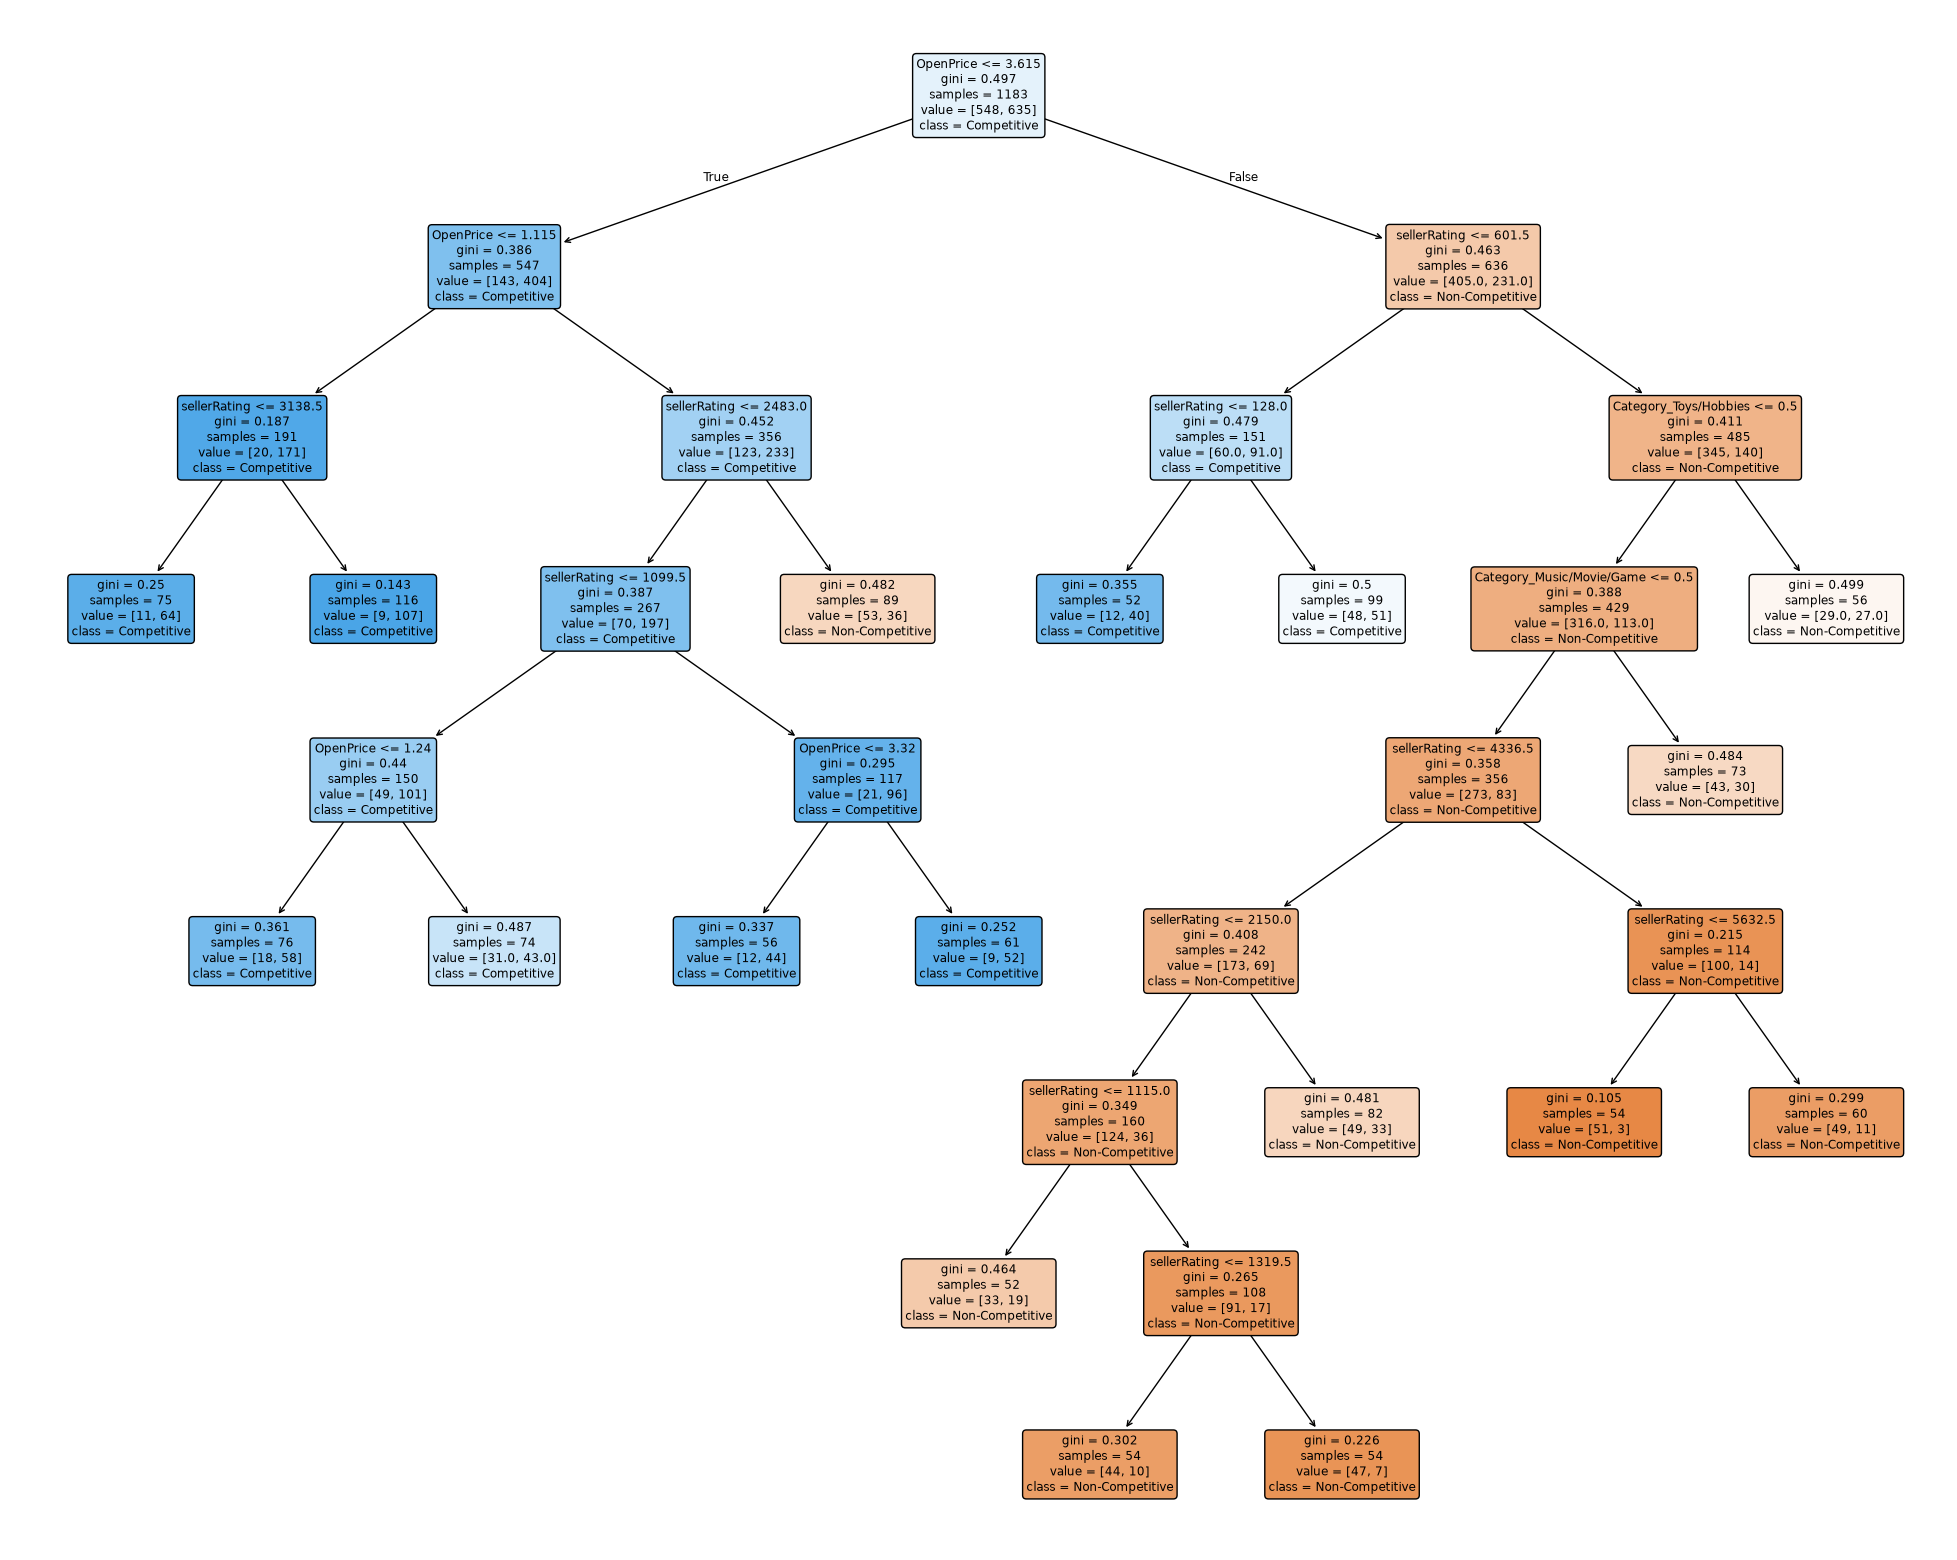

In [133]:
fig = plt.figure(figsize = (25,20))
tree.plot_tree(reducedTreeNoClose,
               feature_names = feature_names,
               class_names = class_names,
               rounded = True,
               filled = True)

fig.savefig("reducedTreeNoClose.png")
plt.show()

### Scatter Plot

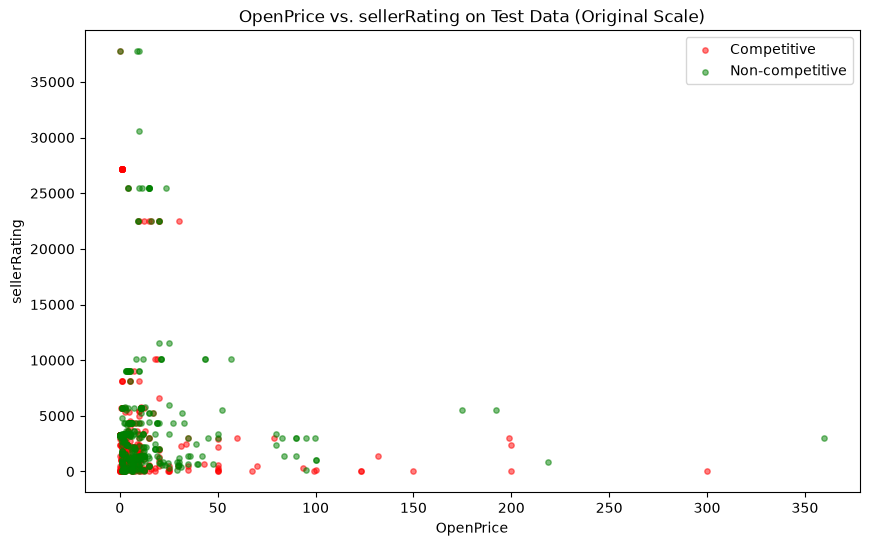

In [146]:
# Plot competitive and non-competitive auctions with test data
competitive = X_test_reduced[y_test_reduced == True]
non_competitive = X_test_reduced[y_test_reduced == False]

plt.figure(figsize = (10, 6))

# We choose the best two predictors: Open price and Seller Rating
plt.scatter(competitive['OpenPrice'],
            competitive['sellerRating'],
            color = 'red', label = 'Competitive',
            s = 15, alpha = 0.5)

plt.scatter(non_competitive['OpenPrice'],
            non_competitive['sellerRating'],
            color = 'green', label = 'Non-competitive',
            s = 15, alpha = 0.5)

plt.xlabel('OpenPrice')
plt.ylabel('sellerRating')
plt.title('OpenPrice vs. sellerRating on Test Data (Original Scale)')
plt.legend()

plt.show()

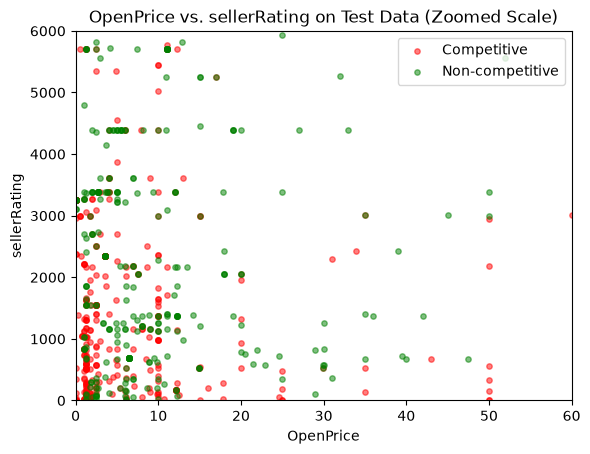

In [135]:
# Zoom in on the area where most auctions are concentrated
# to better visualize the distribution.
plt.scatter(competitive['OpenPrice'],
            competitive['sellerRating'],
            color = 'red', label = 'Competitive',
            s = 15, alpha = 0.5)

plt.scatter(non_competitive['OpenPrice'],
            non_competitive['sellerRating'],
            color = 'green', label = 'Non-competitive',
            s = 15, alpha = 0.5)

plt.xlabel('OpenPrice')
plt.ylabel('sellerRating')
plt.title('OpenPrice vs. sellerRating on Test Data (Zoomed Scale)')
plt.legend()

# Adjust the axis limits for a closer look
plt.xlim(0, 60)
plt.ylim(0, 6000)

plt.show()

### Scatter plot with splitting line

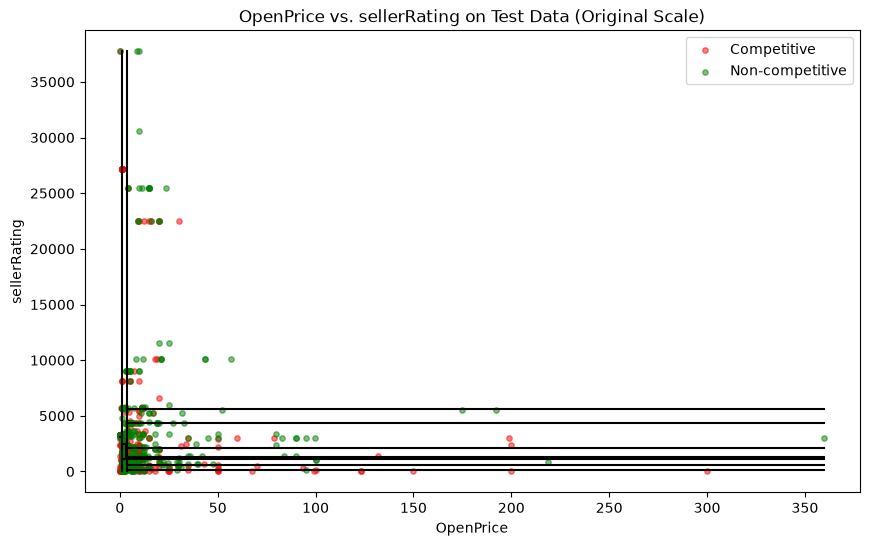

In [147]:
# Plot Scattor plot again with splitting line
plt.figure(figsize = (10, 6))

# We choose the best two predictors: Open price and Seller Rating
# Plot competitive and non-competitive auctions with test data
plt.scatter(competitive['OpenPrice'],
            competitive['sellerRating'],
            color = 'red', label = 'Competitive',
            s = 15, alpha = 0.5)

plt.scatter(non_competitive['OpenPrice'],
            non_competitive['sellerRating'],
            color = 'green', label = 'Non-competitive',
            s = 15, alpha = 0.5)

plt.xlabel('OpenPrice')
plt.ylabel('sellerRating')
plt.title('OpenPrice vs. sellerRating on Test Data (Original Scale)')
plt.legend()

x_max = X_test_reduced['OpenPrice'].max()
y_max = X_test_reduced['sellerRating'].max()

#Root split
plt.plot([3.615, 3.615], [0, y_max], color='black')

# Left branch
plt.plot([1.115, 1.115], [0, y_max], color='black')
plt.plot([0, 1.115], [3138.5, 3138.5], color='black')
plt.plot([1.115, 3.615], [2483, 2483], color='black')
plt.plot([1.115, 3.615], [1099.5, 1099.5], color='black')
plt.plot([1.24, 1.24], [0, 1099.5], color='black')
plt.plot([3.32, 3.32], [1099.5, 2483], color='black')

#Right branch
plt.plot([3.615, x_max], [601.5, 601.5], color='black')
plt.plot([3.615, x_max], [128, 128], color='black')
plt.plot([3.615, x_max], [4336.5, 4336.5], color='black')
plt.plot([3.615, x_max], [5632.5, 5632.5], color='black')
plt.plot([3.615, x_max], [2150, 2150], color='black')
plt.plot([3.615, x_max], [1115, 1115], color='black')
plt.plot([3.615, x_max], [1319.5, 1319.5], color='black')




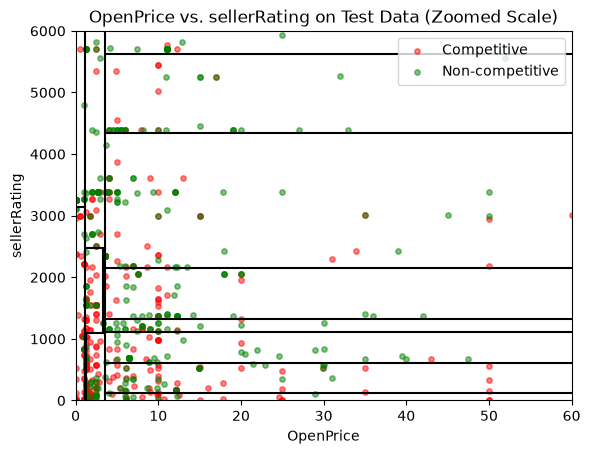

In [148]:
# Zoom in on the area where most auctions are concentrated
# to better visualize the distribution.
plt.scatter(competitive['OpenPrice'],
            competitive['sellerRating'],
            color = 'red', label = 'Competitive',
            s = 15, alpha = 0.5)

plt.scatter(non_competitive['OpenPrice'],
            non_competitive['sellerRating'],
            color = 'green', label = 'Non-competitive',
            s = 15, alpha = 0.5)

plt.xlabel('OpenPrice')
plt.ylabel('sellerRating')
plt.title('OpenPrice vs. sellerRating on Test Data (Zoomed Scale)')
plt.legend()

#Zoom in to 60*6000
plt.xlim(0, 60)
plt.ylim(0, 6000)

x_max = X_test_reduced['OpenPrice'].max()
y_max = X_test_reduced['sellerRating'].max()

#Root split
plt.plot([3.615, 3.615], [0, y_max], color='black')

# Left branch
plt.plot([1.115, 1.115], [0, y_max], color='black')
plt.plot([0, 1.115], [3138.5, 3138.5], color='black')
plt.plot([1.115, 3.615], [2483, 2483], color='black')
plt.plot([1.115, 3.615], [1099.5, 1099.5], color='black')
plt.plot([1.24, 1.24], [0, 1099.5], color='black')
plt.plot([3.32, 3.32], [1099.5, 2483], color='black')

#Right branch
plt.plot([3.615, x_max], [601.5, 601.5], color='black')
plt.plot([3.615, x_max], [128, 128], color='black')
plt.plot([3.615, x_max], [4336.5, 4336.5], color='black')
plt.plot([3.615, x_max], [5632.5, 5632.5], color='black') # 
plt.plot([3.615, x_max], [2150, 2150], color='black')
plt.plot([3.615, x_max], [1115, 1115], color='black')
plt.plot([3.615, x_max], [1319.5, 1319.5], color='black')


plt.show()

## Comparison with k-NN:

In [138]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from dmba import classificationSummary

In [139]:
# Select the same predictors as the final decision tree
keep_cols_knn = list(reducedTreeNoClose.feature_names_in_)

# Retain the existing training and test split
X_train_knn = X_train[keep_cols_knn]
X_test_knn = X_test[keep_cols_knn]

y_train_knn = y_train
y_test_knn = y_test

print("Selected predictors:", keep_cols_knn)

Selected predictors: ['Category_Toys/Hobbies', 'OpenPrice', 'sellerRating', 'Category_Music/Movie/Game']


In [140]:
# Identify numerical and categorical predictors
numeric_features = ['OpenPrice', 'sellerRating']

categorical_features = ['Category_Toys/Hobbies', 'Category_Music/Movie/Game']

# Standardize numerical predictors only
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', 'passthrough', categorical_features)
    ]
)

# Construct k-NN pipeline
knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])

In [141]:
# Set up 5-fold cross-validation
kfold_knn = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Define hyperparameter grid
param_grid_knn = {
    'knn__n_neighbors': list(range(1, 60)),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['manhattan', 'euclidean']
}

# Grid search
grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    scoring='accuracy',
    cv=kfold_knn,
    n_jobs=-1,
    return_train_score=True
)

# Fit using training data only
grid_knn.fit(X_train_knn, y_train_knn)

# Report best parameters
print("Best hyperparameters:", grid_knn.best_params_)

print(
    "Best cross-validation accuracy:",
    round(grid_knn.best_score_, 4)
)

Best hyperparameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 34, 'knn__weights': 'distance'}
Best cross-validation accuracy: 0.7202


In [142]:
# Extract grid search results
cv_results_knn = pd.DataFrame(grid_knn.cv_results_)

cv_summary_knn = cv_results_knn[[
    'param_knn__n_neighbors',
    'param_knn__weights',
    'param_knn__metric',
    'mean_train_score',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]].copy()

# Rename columns for presentation
cv_summary_knn.columns = [
    'k',
    'Weights',
    'Distance',
    'Mean Training Accuracy',
    'Mean CV Accuracy',
    'CV Standard Deviation',
    'Rank'
]


In [143]:
best_by_setting_knn = (
    cv_summary_knn
    .sort_values('Mean CV Accuracy', ascending=False)
    .groupby(['Weights', 'Distance'])
    .head(1)
    .reset_index(drop=True)
)

display(best_by_setting_knn)

,k,Weights,Distance,Mean Training Accuracy,Mean CV Accuracy,CV Standard Deviation,Rank
0,34,distance,manhattan,0.910820,0.720207,0.011341,1
1,47,distance,euclidean,0.910820,0.716828,0.015899,11
2,6,uniform,manhattan,0.766696,0.693145,0.020392,115
3,9,uniform,euclidean,0.751900,0.689738,0.033207,116


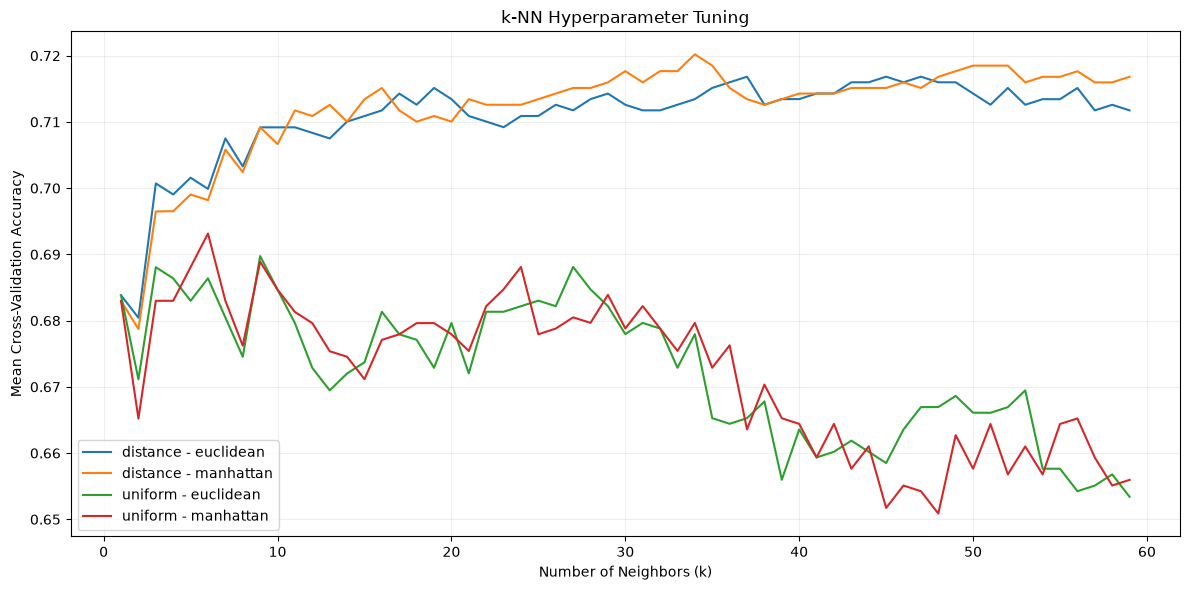

In [144]:
plt.figure(figsize=(12, 6))

for (weights, metric), group in cv_summary_knn.groupby(
    ['Weights', 'Distance']
):
    group = group.sort_values('k')

    plt.plot(
        group['k'],
        group['Mean CV Accuracy'],
        label=f'{weights} - {metric}',
        linewidth=1.5
    )

# Highlight optimal hyperparameter setting
best_k = grid_knn.best_params_['knn__n_neighbors']
best_cv_accuracy = grid_knn.best_score_


plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean Cross-Validation Accuracy')
plt.title('k-NN Hyperparameter Tuning')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [145]:
# Extract the best k-NN model
knn_final = grid_knn.best_estimator_

# Generate predictions
y_train_pred_knn = knn_final.predict(X_train_knn)
y_test_pred_knn = knn_final.predict(X_test_knn)

# Predictions from the final decision tree
y_test_pred_tree = reducedTreeNoClose.predict(X_test_knn)

# Test Accuracy and Confusion matrix
print("\nFinal Decision Tree")
classificationSummary(y_test_knn, y_test_pred_tree)

print("\nk-NN")
classificationSummary(y_test_knn, y_test_pred_knn)



Final Decision Tree
Confusion Matrix (Accuracy 0.7224)

       Prediction
Actual   0   1
     0 263  95
     1 124 307

k-NN
Confusion Matrix (Accuracy 0.7186)

       Prediction
Actual   0   1
     0 254 104
     1 118 313
